In [1]:
# Based on the following works:

# Raissi, M., Perdikaris, P., & Karniadakis, G. E. (2019).
# Physics-informed neural networks: A deep learning framework for solving
# forward and inverse problems involving nonlinear partial differential equations.
# Journal of Computational Physics, 378, 686–707.
# https://doi.org/10.1016/j.jcp.2018.10.045

# MikelUnizar. (2025). AMB-PINNs [GitHub repository].
# Retrieved January 26, 2026, from https://github.com/mikelunizar/AMB-PINNs

In [2]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join(os.path.dirname(os.getcwd()))))
sys.path.append(os.path.abspath(os.path.join(os.path.dirname(os.getcwd()), 'model')))
sys.path.append(os.path.abspath(os.path.join(os.path.dirname(os.getcwd()), '../../src')))

In [3]:
import torch
import numpy as np 
import torch.nn as nn
import matplotlib.pyplot as plt

# TensOps library
import tensopsciml as to
from tensopsciml.tensors import TensOps, MetrOps

from architecture.PINN_architecture import PINN
from trainers.train import train_pinn_finite_differences, train_pinn_finite_autograd
from utils.plots import plot_model_comparison

torch.manual_seed(123)
np.random.seed(123)

In [4]:
def underdamped_oscillator(d, w0, t, x0=1.0, v0=0.0):
    """
    Analytical solution for an underdamped harmonic oscillator.
    Equation: x'' + 2d*x' + w0^2*x = 0
    """
    assert d < w0, "System is not underdamped (d must be < w0)"
    
    # w is the damped angular frequency: w = sqrt(w0^2 - d^2)
    w = torch.sqrt(torch.tensor(w0**2 - d**2))
    
    # General solution constants for x(0)=x0, x'(0)=v0
    # x(t) = exp(-d*t) * (A*cos(wt) + B*sin(wt))
    A = x0
    B = (v0 + d * x0) / w
    
    x = torch.exp(-d * t) * (A * torch.cos(w * t) + B * torch.sin(w * t))
    return x

In [5]:
# Parameters
d, w0 = 2, 20
t_max = 1.0

n_samples = 100
mu, k = 2*d, w0**2

# Generate Data
t_analytic_ = torch.linspace(0, t_max, 500).view(-1, 1)
x_analytic_ = underdamped_oscillator(d, w0, t_analytic_)

t_analytic = TensOps(t_analytic_.unsqueeze(1), domain_dim=1, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None)
x_analytic = TensOps(x_analytic_.unsqueeze(1), domain_dim=1, codomain_dim=[1], order=[0, 0], contravariant_indices=None, covariant_indices=None)

# Training data: 10 points sampled from the domain
t_data = t_analytic_[0:200:20]
x_data = x_analytic_[0:200:20]

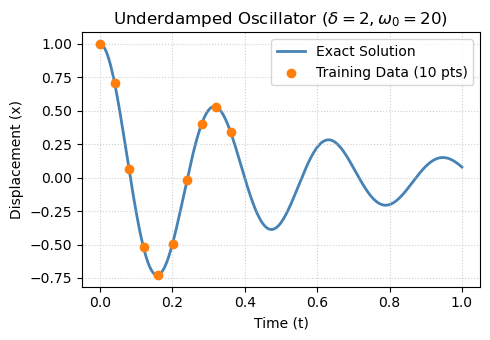

In [6]:
plt.figure(figsize=(5, 3.5))

# Plot analytic solution and training data
plt.plot(t_analytic_, x_analytic_, label="Exact Solution", color='steelblue', lw=2, zorder=1)
plt.scatter(t_data, x_data, color="tab:orange", label=f"Training Data ({len(t_data)} pts)", zorder=2)

plt.title(fr"Underdamped Oscillator ($\delta={d}, \omega_0={w0}$)")
plt.xlabel("Time (t)")
plt.ylabel("Displacement (x)")

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()

plt.show()

In [7]:
collocation_points = torch.linspace(0, 1, n_samples).view(-1, 1)

In [8]:
# Finite-difference scheme to derivate physics loss

t_physics_fd_ = collocation_points.clone()
dt = t_physics_fd_[1] - t_physics_fd_[0]
Dt = to.kernels.Derivative(dt).one_dimension().requires_grad_(False)

n_derivative = t_physics_fd_.shape[0] - 1

metric_t = MetrOps(torch.ones(1, 1, 1, n_derivative), domain_dim=1, codomain_dim=[1, 1])
inv_metric_t = to.inverse(metric_t)  # g^{ab}

e_t = TensOps(torch.ones(1, 1, n_derivative), domain_dim=1, codomain_dim=[1],
              order=[1, 0], contravariant_indices=[0], covariant_indices=None)

model_finite_diff = PINN()
optimizer = torch.optim.Adam(model_finite_diff.parameters(), lr=1e-4)

train_pinn_finite_differences(model_finite_diff, optimizer, t_data, x_data, t_physics_fd_, mu, k, Dt, inv_metric_t, e_t, iterations=100000)

Iter  10000 | Data: 1.321e-02 | Phys: 4.148e+02 | Total: 5.469e+02
Iter  20000 | Data: 7.551e-05 | Phys: 2.089e+01 | Total: 2.164e+01
Iter  30000 | Data: 7.966e-06 | Phys: 5.927e-01 | Total: 6.723e-01
Iter  40000 | Data: 7.405e-06 | Phys: 2.447e-01 | Total: 3.187e-01
Iter  50000 | Data: 7.452e-06 | Phys: 1.453e-01 | Total: 2.198e-01
Iter  60000 | Data: 7.452e-06 | Phys: 1.041e-01 | Total: 1.786e-01
Iter  70000 | Data: 7.321e-06 | Phys: 8.209e-02 | Total: 1.553e-01
Iter  80000 | Data: 7.387e-06 | Phys: 6.771e-02 | Total: 1.416e-01
Iter  90000 | Data: 7.246e-06 | Phys: 5.969e-02 | Total: 1.322e-01
Iter 100000 | Data: 7.813e-06 | Phys: 5.246e-02 | Total: 1.306e-01


In [9]:
# Autograd scheme to derivate physics loss
t_physics_ag_ = collocation_points.clone().requires_grad_(True)


t_physics_ag = TensOps(t_physics_ag_.unsqueeze(1), domain_dim=1, codomain_dim=[1],
                       order=[1, 0], contravariant_indices=[0], covariant_indices=None)

metric_ag = MetrOps(torch.ones(n_samples, 1, 1, 1), domain_dim=1, codomain_dim=[1, 1])
inv_metric_ag = to.inverse(metric_ag)  # g^{ab}

e_t_ag = TensOps(torch.ones(n_samples, 1, 1), domain_dim=1, codomain_dim=[1],
                 order=[1, 0], contravariant_indices=[0], covariant_indices=None)

model_autograd = PINN()
optimizer = torch.optim.Adam(model_autograd.parameters(), lr=1e-4)

train_pinn_finite_autograd(model_autograd, optimizer, t_data, x_data, t_physics_ag, mu, k, inv_metric_ag, e_t_ag, iterations=100000)

Iter  10000 | Data: 6.784e-02 | Phys: 5.044e+02 | Total: 1.183e+03
Iter  20000 | Data: 4.617e-04 | Phys: 8.967e+01 | Total: 9.429e+01
Iter  30000 | Data: 1.925e-05 | Phys: 5.682e+00 | Total: 5.874e+00
Iter  40000 | Data: 7.795e-08 | Phys: 4.452e-01 | Total: 4.460e-01
Iter  50000 | Data: 3.344e-08 | Phys: 2.587e-01 | Total: 2.591e-01
Iter  60000 | Data: 1.157e-08 | Phys: 1.881e-01 | Total: 1.882e-01
Iter  70000 | Data: 6.390e-09 | Phys: 1.507e-01 | Total: 1.507e-01
Iter  80000 | Data: 4.937e-09 | Phys: 1.277e-01 | Total: 1.278e-01
Iter  90000 | Data: 4.613e-09 | Phys: 1.135e-01 | Total: 1.136e-01
Iter 100000 | Data: 1.652e-08 | Phys: 1.052e-01 | Total: 1.053e-01


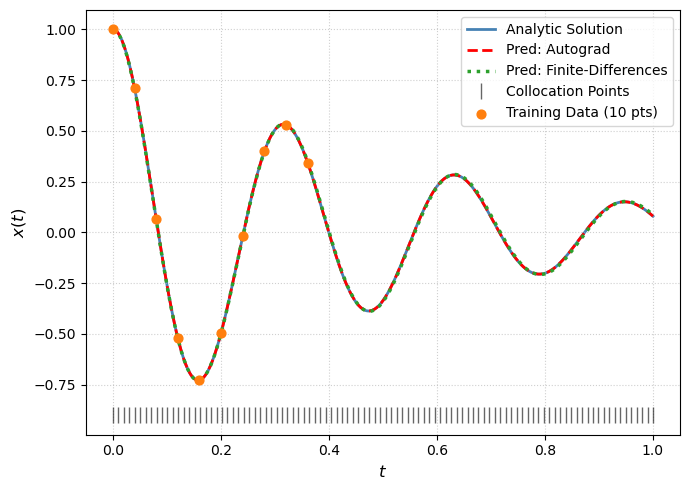

In [10]:
plot_model_comparison(t_analytic, x_analytic, model_autograd, model_finite_diff, t_data, x_data, collocation_points)